# Tarea 1 – Parte 1: Recolección y limpieza de noticias

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

## Configuración inicial

| Parámetro | Valor |
| :--- | :--- |
| **Fecha de descarga** | 17 de octubre de 2026 (también queda en `FECHA_DESCARGA` al ejecutar) |
| **Opción elegida** | **C – Comparada**: La República + El Comercio (~200 noticias de cada medio) |
| **Categorías finales** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| **URL base La República** | `https://larepublica.pe` |
| **URL base El Comercio** | `https://elcomercio.pe` |

### Fuentes

| Medio | Fuente | URLs |
| :--- | :--- | :--- |
| El Comercio | Sitemaps web por sección (últimas 100 notas de cada una) | `https://elcomercio.pe/sitemap/web/{politica, economia, deporte-total, tecnologia}/?outputType=xml` |
| La República | RSS oficiales | `https://larepublica.pe/rss/{politica, economia, deportes, ciencia, home}.xml` |
| La República | News sitemaps | `https://larepublica.pe/sitemap/{politica, economia, deportes, ciencia}.xml` |
| La República | Portadas de sección | `https://larepublica.pe/{politica, economia, deportes, ciencia, tecnologia}` |

### Estrategia de extracción (y por qué)

1. **El Comercio** publica un sitemap por sección con sus últimas 100 notas. Es la fuente más limpia: de cada
   sitemap se toma una muestra aleatoria (`SEED = 42`) y de cada nota se leen el titular (`<h1>`), la bajada
   (`og:description`) y la fecha (`article:published_time`).
2. **La República** solo expone en RSS y sitemaps las últimas ~48 horas (entre 7 y 25 notas por sección), y su
   `robots.txt` **prohíbe** la paginación de secciones (`/*/pag/*`, `/*/*/page/*`), el archivo (`/archivo/*`) y la
   API interna que usa el botón "cargar más" (`/data/*`). Por eso:
   - las fuentes oficiales se usan solo como **semillas**, y
   - se recorre el **grafo de enlaces relacionados**: cada nota enlaza a otras de su misma sección. Es un
     rastreo en anchura con una cola por categoría que se atiende en *round-robin* (el corpus queda balanceado)
     y que saca primero las notas más recientes (la fecha viene en la URL), para que ambos medios cubran una
     ventana temporal parecida.
3. **Buenas prácticas:** cada URL se valida contra `robots.txt` antes de pedirla, `User-Agent` descriptivo,
   pausa aleatoria de 1–2 s después de cada petición, máximo 1 reintento, log de todas las peticiones y
   respaldo crudo en `datos/raw/`.
4. **Reproducibilidad:** cada respuesta exitosa se guarda en una caché local (`datos/raw/html/`, fuera de Git
   por su tamaño). Si ya existe el respaldo crudo y `RE_SCRAPE = False`, el notebook se ejecuta completo sin
   volver a pedirle nada a los medios.

In [1]:
import gzip
import hashlib
import heapq
import json
import random
import re
import time
from collections import Counter
from datetime import date, datetime
from pathlib import Path
from urllib.parse import urljoin, urlparse

import feedparser
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup
from IPython.display import display
from protego import Protego

# Plotly interactivo en Jupyter + imagen PNG estática para que los gráficos se vean en GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 500
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 120)

FECHA_DESCARGA = date.today().isoformat()
SEED = 42
RE_SCRAPE = False            # True fuerza un scraping nuevo aunque exista el respaldo crudo
USER_AGENT = ("Tarea1-PythonIntermedio/1.0 (proyecto academico de clasificacion de titulares; "
              "scraping respetuoso; github.com/rodnm)")
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
META_POR_SECCION = 60        # notas por sección y medio: ~50 quedan tras la limpieza
MAX_ARTICULOS_LR = 500       # tope de seguridad del rastreo de La República

RAW = Path("datos/raw")
CACHE_HTML = RAW / "html"
CACHE_HTML.mkdir(parents=True, exist_ok=True)
RUTA_CRUDO = RAW / "articulos_crudos.csv"
RUTA_LOG = RAW / "log_peticiones.csv"
RUTA_NO_NOTAS = RAW / "urls_no_nota.csv"

random.seed(SEED)
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-17


## 1. Cliente HTTP respetuoso

`urllib.robotparser`, de la librería estándar, **no entiende comodines** (`*`, `$`), y La República los usa
(`/*/pag/*`). Con ese parser, `/politica/pag/2` aparecería como permitido. Por eso se usa `protego`, el intérprete
de `robots.txt` de Scrapy, que sí implementa los comodines.

La función `obtener()` concentra todas las reglas: valida `robots.txt`, hace una pausa de 1–2 s después de cada
petición, reintenta como máximo una vez (y nunca ante un 403/404/410, que son definitivos), registra cada petición
en el log y guarda en caché solo las respuestas 200. Una página en caché es, entonces, una URL que funcionó.

In [2]:
ROBOTS = {}
LOG = []


def reglas_robots(dominio):
    """Lee robots.txt una vez por dominio y guarda una copia cruda."""
    if dominio not in ROBOTS:
        ruta = RAW / f"robots_{dominio}.txt"
        if ruta.exists() and not RE_SCRAPE:
            texto = ruta.read_text(encoding="utf-8")
        else:
            texto = session.get(f"https://{dominio}/robots.txt", timeout=20).text
            ruta.write_text(texto, encoding="utf-8")
            time.sleep(random.uniform(1, 2))
        ROBOTS[dominio] = Protego.parse(texto)
    return ROBOTS[dominio]


def ruta_cache(url):
    return CACHE_HTML / f"{hashlib.sha1(url.encode()).hexdigest()}.html.gz"


def obtener(url):
    """GET respetuoso. Devuelve el texto de la respuesta o None si no se pudo obtener."""
    cache = ruta_cache(url)
    if cache.exists() and not RE_SCRAPE:
        return gzip.decompress(cache.read_bytes()).decode("utf-8")
    if not reglas_robots(urlparse(url).netloc).can_fetch(url, USER_AGENT):
        LOG.append({"url": url, "estado": "bloqueado_robots", "intento": 0,
                    "hora": datetime.now().isoformat(timespec="milliseconds")})
        return None
    for intento in (1, 2):                       # 1 intento + máximo 1 reintento
        try:
            r = session.get(url, timeout=25)
            estado = r.status_code
        except requests.RequestException as e:
            r, estado = None, f"error:{type(e).__name__}"
        LOG.append({"url": url, "estado": estado, "intento": intento,
                    "hora": datetime.now().isoformat(timespec="milliseconds")})
        time.sleep(random.uniform(1, 2))
        if estado == 200:
            cache.write_bytes(gzip.compress(r.content))
            return r.content.decode("utf-8", errors="replace")   # ambos medios sirven UTF-8
        if estado in (403, 404, 410):            # errores definitivos: no se reintenta
            return None
    return None


pruebas = [
    "https://larepublica.pe/rss/politica.xml",
    "https://larepublica.pe/economia/2026/10/16/ejemplo-123",
    "https://larepublica.pe/politica/pag/2",
    "https://larepublica.pe/data/noticias",
    "https://larepublica.pe/archivo/2026",
    "https://elcomercio.pe/sitemap/web/politica/?outputType=xml",
    "https://elcomercio.pe/buscar/congreso/",
]
display(pd.DataFrame({
    "url": pruebas,
    "permitido": [reglas_robots(urlparse(u).netloc).can_fetch(u, USER_AGENT) for u in pruebas],
}))

,url,permitido
0,https://larepublica.pe/rss/politica.xml,True
1,https://larepublica.pe/economia/2026/10/16/ejemplo-123,True
2,https://larepublica.pe/politica/pag/2,False
3,https://larepublica.pe/data/noticias,False
4,https://larepublica.pe/archivo/2026,False
5,https://elcomercio.pe/sitemap/web/politica/?outputType=xml,True
6,https://elcomercio.pe/buscar/congreso/,False


## 2. Funciones de extracción

* **`seccion_original`** se toma de la ruta de la URL, que es como cada diario clasifica la nota en su web:
  `elcomercio.pe/deporte-total/futbol-peruano/...-noticia/` → `deporte-total/futbol-peruano` y
  `larepublica.pe/economia/2026/10/16/...` → `economia`.
* **Titular:** `<h1>` (lo que ve el lector); si falta, `og:title`. **Bajada:** `og:description`.
  **Fecha:** `article:published_time` (El Comercio) o `datePublished` del JSON-LD (La República, que no publica
  la etiqueta `meta`).

In [3]:
PATRON_LR = re.compile(r"^https://larepublica\.pe/(?P<seccion>[a-z0-9-]+(?:/[a-z0-9-]+)*)/"
                       r"(?P<fecha>20\d{2}/\d{2}/\d{2})/[a-z0-9-]+$")
PATRON_EC = re.compile(r"^https://elcomercio\.pe/(?P<seccion>[a-z0-9-]+(?:/[a-z0-9-]+)*)/"
                       r"[a-z0-9-]+-noticia/?$")
SUFIJO_MEDIO = re.compile(r"\s*\|\s*(El Comercio( Perú)?|La República)\s*$", re.IGNORECASE)


def normalizar_lr(url):
    """URL canónica de La República: absoluta, sin parámetros, sin /amp/ ni barra final."""
    url = urljoin("https://larepublica.pe", url.strip()).split("#")[0].split("?")[0].rstrip("/")
    return url.replace("https://larepublica.pe/amp/", "https://larepublica.pe/")


def seccion_de_url(url):
    m = PATRON_LR.match(url) or PATRON_EC.match(url)
    return m["seccion"] if m else None


def fecha_json_ld(soup):
    for script in soup.find_all("script", type="application/ld+json"):
        try:
            datos = json.loads(script.string or "")
        except json.JSONDecodeError:
            continue
        nodos = datos if isinstance(datos, list) else datos.get("@graph", [datos])
        for nodo in nodos:
            if isinstance(nodo, dict) and nodo.get("datePublished"):
                return nodo["datePublished"]
    return None


def parsear_articulo(html, url, medio):
    soup = BeautifulSoup(html, "lxml")

    def meta(clave):
        tag = soup.find("meta", property=clave) or soup.find("meta", attrs={"name": clave})
        return tag["content"].strip() if tag and tag.get("content") else None

    h1 = soup.find("h1")
    titular = h1.get_text(" ", strip=True) if h1 else (meta("og:title") or "")
    fecha = meta("article:published_time") or fecha_json_ld(soup)
    return {
        "titular": SUFIJO_MEDIO.sub("", titular),
        "bajada": meta("og:description") or meta("description") or "",
        "medio": medio,
        "seccion_original": seccion_de_url(url),
        "url": url,
        "fecha": fecha[:10] if fecha else None,
    }

## 3. El Comercio: sitemaps por sección

Del sitemap de cada sección se descartan antes de pedirlas las URLs que no son notas (videos o galerías, que no
terminan en `-noticia/`) y se toma una muestra aleatoria de `META_POR_SECCION` notas.

In [4]:
EC_SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]


def recolectar_ec():
    registros, no_notas = [], []
    for seccion in EC_SECCIONES:
        xml = obtener(f"https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml")
        if not xml:
            print(f"  sitemap {seccion}: sin respuesta")
            continue
        (RAW / f"ec_sitemap_{seccion}.xml").write_text(xml, encoding="utf-8")
        locs = re.findall(r"<loc>\s*([^<\s]+)\s*</loc>", xml)
        notas = [u for u in locs if PATRON_EC.match(u)]
        no_notas += [{"medio": "El Comercio", "url": u} for u in locs if not PATRON_EC.match(u)]
        muestra = random.Random(SEED).sample(notas, min(META_POR_SECCION, len(notas)))
        print(f"  sitemap {seccion:<14}: {len(locs)} URLs, {len(notas)} notas, muestra de {len(muestra)}")
        for url in muestra:
            html = obtener(url)
            if html:
                registros.append({**parsear_articulo(html, url, "El Comercio"),
                                  "fuente": f"sitemap_ec:{seccion}"})
    return registros, no_notas

## 4. La República: semillas + rastreo de enlaces relacionados

* **Semillas:** RSS, news sitemaps y portadas de sección. El RSS `home.xml` mezcla todas las secciones del diario;
  sus notas de otras secciones (mundo, sociedad, espectáculos…) se guardan tal cual para **documentar en la
  limpieza las noticias que no encajan** en las 4 categorías.
* **Rastreo:** cada categoría tiene su propia cola de prioridad (un *heap* ordenado por la fecha de la URL, la
  más reciente primero). En cada vuelta se atiende una nota de cada categoría que todavía no llegó a la meta,
  y los enlaces a notas de las secciones objetivo que aparecen en ella se agregan a la cola correspondiente.

In [5]:
LR_SECCION_A_CATEGORIA = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}


def categoria_rastreo(url):
    seccion = seccion_de_url(url)
    return LR_SECCION_A_CATEGORIA.get(seccion.split("/")[0]) if seccion else None


def enlaces_lr(html):
    soup = BeautifulSoup(html, "lxml")
    urls = {normalizar_lr(a["href"]) for a in soup.find_all("a", href=True)}
    return {u for u in urls if PATRON_LR.match(u)}


def semillas_lr():
    urls, otras_secciones = set(), []
    for nombre in ["politica", "economia", "deportes", "ciencia", "home"]:
        xml = obtener(f"https://larepublica.pe/rss/{nombre}.xml")
        if not xml:
            continue
        (RAW / f"lr_rss_{nombre}.xml").write_text(xml, encoding="utf-8")
        for item in feedparser.parse(xml).entries:
            url = normalizar_lr(item.link)
            if categoria_rastreo(url):
                urls.add(url)
            elif PATRON_LR.match(url):
                publicada = item.get("published_parsed")
                otras_secciones.append({
                    "titular": item.title.strip(), "bajada": "", "medio": "La Republica",
                    "seccion_original": seccion_de_url(url), "url": url,
                    "fecha": time.strftime("%Y-%m-%d", publicada) if publicada else None,
                    "fuente": f"rss_lr:{nombre}",
                })
    for nombre in ["politica", "economia", "deportes", "ciencia"]:
        xml = obtener(f"https://larepublica.pe/sitemap/{nombre}.xml")
        if xml:
            (RAW / f"lr_sitemap_{nombre}.xml").write_text(xml, encoding="utf-8")
            locs = (normalizar_lr(u) for u in re.findall(r"<loc>\s*([^<\s]+)\s*</loc>", xml))
            urls.update(u for u in locs if categoria_rastreo(u))
    for nombre in ["politica", "economia", "deportes", "ciencia", "tecnologia"]:
        html = obtener(f"https://larepublica.pe/{nombre}")
        if html:
            urls.update(u for u in enlaces_lr(html) if categoria_rastreo(u))
    return urls, otras_secciones


def rastrear_lr(semillas):
    colas = {c: [] for c in CATEGORIAS}
    vistos, registros, conteo = set(), [], Counter()

    def encolar(url):
        categoria = categoria_rastreo(url)
        if categoria and url not in vistos:
            vistos.add(url)
            fecha = int(PATRON_LR.match(url)["fecha"].replace("/", ""))
            heapq.heappush(colas[categoria], (-fecha, url))   # fecha negativa: la más reciente sale primero

    for url in sorted(semillas):
        encolar(url)
    print("Cola inicial por categoría:", {c: len(q) for c, q in colas.items()})

    procesados, inicio = 0, time.time()
    while procesados < MAX_ARTICULOS_LR:
        pendientes = [c for c in CATEGORIAS if conteo[c] < META_POR_SECCION and colas[c]]
        if not pendientes:
            break
        for categoria in pendientes:             # round-robin: una nota por categoría en cada vuelta
            _, url = heapq.heappop(colas[categoria])
            html = obtener(url)
            procesados += 1
            if not html:
                continue
            registros.append({**parsear_articulo(html, url, "La Republica"), "fuente": "rastreo_lr"})
            conteo[categoria] += 1
            for enlace in enlaces_lr(html):
                encolar(enlace)
    print(f"Rastreo terminado: {procesados} notas procesadas en {time.time() - inicio:.0f} s → {dict(conteo)}")
    return registros

## 5. Ejecución del scraping (o carga del respaldo crudo)

Si `datos/raw/articulos_crudos.csv` ya existe y `RE_SCRAPE = False`, se carga el respaldo en lugar de volver a
descargar. El log de peticiones se conserva para documentar cuándo se hizo el scraping y con qué pausas.

In [6]:
if RUTA_CRUDO.exists() and not RE_SCRAPE:
    crudo = pd.read_csv(RUTA_CRUDO)
    no_notas = pd.read_csv(RUTA_NO_NOTAS)
    log = pd.read_csv(RUTA_LOG)
    print(f"Respaldo crudo cargado: {len(crudo)} registros (RE_SCRAPE = False).")
else:
    print("El Comercio:")
    registros_ec, urls_no_nota = recolectar_ec()
    print("La República:")
    semillas, otras_secciones_lr = semillas_lr()
    print(f"  URLs semilla en las secciones objetivo: {len(semillas)}")
    registros_lr = rastrear_lr(semillas)

    crudo = pd.DataFrame(registros_ec + registros_lr + otras_secciones_lr)
    no_notas = pd.DataFrame(urls_no_nota, columns=["medio", "url"])
    log = pd.DataFrame(LOG)
    crudo.to_csv(RUTA_CRUDO, index=False, encoding="utf-8")
    no_notas.to_csv(RUTA_NO_NOTAS, index=False, encoding="utf-8")
    log.to_csv(RUTA_LOG, index=False, encoding="utf-8")
    print(f"Respaldo crudo guardado: {len(crudo)} registros en {RUTA_CRUDO}")

horas = pd.to_datetime(log["hora"])
print(f"\nScraping: {len(log)} peticiones HTTP entre {horas.min():%Y-%m-%d %H:%M} y {horas.max():%H:%M} "
      f"| pausa mediana entre peticiones: {horas.diff().dt.total_seconds().median():.1f} s")
display(log["estado"].astype(str).value_counts().rename_axis("estado HTTP").to_frame("peticiones"))
display(crudo.groupby(["medio", "fuente"]).size().rename("registros").to_frame())

Respaldo crudo cargado: 627 registros (RE_SCRAPE = False).

Scraping: 498 peticiones HTTP entre 2026-10-17 10:49 y 11:08 | pausa mediana entre peticiones: 2.1 s


,peticiones
estado HTTP,
200,498


registros
medio        fuente                             
El Comercio  sitemap_ec:deporte-total         60
             sitemap_ec:economia              60
             sitemap_ec:politica              60
             sitemap_ec:tecnologia            60
La Republica rastreo_lr                      240
             rss_lr:home                     147

## 6. Limpieza y normalización

Pasos, en este orden, registrando cuántas filas elimina cada uno:

1. URLs del sitemap que no son notas (videos y galerías; se descartaron antes de pedirlas).
2. URLs duplicadas.
3. Titulares vacíos.
4. Titulares duplicados con distinta URL (el diario a veces republica la misma nota).
5. Notas sin fecha de publicación.
6. Secciones que no encajan en las 4 categorías y columnas de opinión (ver la tabla de equivalencias).
7. **Titulares de plantilla:** series diarias que repiten el mismo titular cambiando solo la fecha (*"Precio del
   dólar hoy en Perú, miércoles 14 de octubre..."*). Se conserva una sola nota por serie, la más reciente. Si
   quedaran todas, algunas caerían en train y otras en test, y el modelo "acertaría" por memoria: es una fuga de
   datos.

In [7]:
df = crudo.copy()
for columna in ["titular", "bajada"]:
    df[columna] = (df[columna].fillna("").astype(str)
                   .str.replace(r"\s+", " ", regex=True).str.strip())
descartes = []


def registrar(motivo, filas, columna="titular"):
    ejemplo = str(filas[columna].iloc[0])[:90] if len(filas) else ""
    descartes.append({"motivo": motivo, "n": len(filas), "ejemplo": ejemplo})


registrar("URL del sitemap que no es nota (video o galería)", no_notas, columna="url")

registrar("URL duplicada", df[df.duplicated("url")])
df = df.drop_duplicates("url")

registrar("Titular vacío", df[df["titular"] == ""])
df = df[df["titular"] != ""]

registrar("Titular duplicado (otra URL)", df[df.duplicated("titular")])
df = df.drop_duplicates("titular")

registrar("Sin fecha de publicación", df[df["fecha"].isna()])
df = df[df["fecha"].notna()]
print(f"Filas tras quitar duplicados, vacíos y notas sin fecha: {len(df)} (de {len(crudo)} registros crudos)")

Filas tras quitar duplicados, vacíos y notas sin fecha: 627 (de 627 registros crudos)


### Tabla de equivalencias `seccion_original` → `etiqueta`

* Se mapea por la **sección madre** (primer segmento de la ruta). Las subsecciones heredan la categoría de su
  sección madre: `economia/mercados` → `economia`, `politica/congreso` → `politica`.
* `deporte-total` es el nombre de la sección de deportes de El Comercio.
* `elecciones` (El Comercio) se mapea a `politica`. Algunas notas aparecen en el sitemap de una sección pero su URL
  pertenece a otra (`ecdata`, la unidad de datos; `bbc-news-mundo`; `ruedas-tuercas`): la regla es la ruta de la
  URL, así que se descartan.
* `ciencia` (La República) y `tecnologia` (El Comercio, que incluye subsecciones como `tecnologia/ciencias` o
  `tecnologia/ecologia`) se unifican en `ciencia_tecnologia`.
* **Regla explícita:** las columnas de opinión (`*/opinion`) se descartan aunque su sección encaje. Son textos de
  autor, no noticias, y su estilo de titular es distinto.
* **Subsecciones excluidas:** `tecnologia/streamers` (El Comercio) cubre personajes de internet y farándula
  digital, no ciencia ni tecnología. Se detectó en la auditoría humana del notebook 02: el caso *"¡Ya güey!: Edgar,
  niño cuya caída se convirtió en fenómeno viral hace 20 años, se casa"* no encaja en ninguna de las 4 categorías.
  Heredar la categoría de la sección madre es una buena regla general, pero no infalible.
* Cualquier otra sección (sociedad, mundo, espectáculos…) se descarta. **No se crea una quinta categoría.**

In [8]:
MAPEO_SECCION = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "deporte-total": "deportes",
    "elecciones": "politica",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}
SUBSECCIONES_EXCLUIDAS = {"tecnologia/streamers"}

df["seccion_madre"] = df["seccion_original"].fillna("(sin sección)").str.split("/").str[0]
df["etiqueta"] = df["seccion_madre"].map(MAPEO_SECCION)
es_opinion = df["seccion_original"].fillna("").str.contains(r"(?:^|/)opinion(?:/|$)")
es_excluida = df["seccion_original"].isin(SUBSECCIONES_EXCLUIDAS)

tabla_mapeo = (df.assign(etiqueta=df["etiqueta"].where(~es_opinion, "— descartada (opinión) —")
                         .where(~es_excluida, "— descartada (subsección excluida) —")
                         .fillna("— descartada (fuera de las 4) —"))
                 .groupby(["medio", "seccion_original", "etiqueta"]).size().rename("noticias")
                 .reset_index().sort_values(["medio", "etiqueta", "noticias"], ascending=[True, True, False]))
display(tabla_mapeo.reset_index(drop=True))

fuera = df[df["etiqueta"].isna()]
secciones_fuera = ", ".join(sorted(fuera["seccion_madre"].unique()))
registrar(f"Sección fuera de las 4 categorías ({secciones_fuera})", fuera)
df = df[df["etiqueta"].notna()]

opinion = df[es_opinion.loc[df.index]]
registrar("Columna de opinión (no es noticia)", opinion)
df = df.drop(opinion.index).copy()

excluidas = df[es_excluida.loc[df.index]]
registrar(f"Subsección excluida ({', '.join(sorted(SUBSECCIONES_EXCLUIDAS))})", excluidas)
df = df.drop(excluidas.index).copy()

# Titulares de plantilla: se comparan sin números ni nombres de días o meses
FECHAS_EN_TEXTO = (r"\b(hoy|lunes|martes|miércoles|jueves|viernes|sábado|domingo|enero|febrero|marzo|abril|mayo|"
                   r"junio|julio|agosto|septiembre|setiembre|octubre|noviembre|diciembre)\b")
df["plantilla"] = (df["titular"].str.lower().str.replace(FECHAS_EN_TEXTO, " ", regex=True)
                   .str.replace(r"\d+", " ", regex=True).str.replace(r"\W+", " ", regex=True).str.strip())
df = df.sort_values("fecha", ascending=False)        # de cada serie se conserva la nota más reciente
repetidas = df[df.duplicated("plantilla")]
registrar("Titular de plantilla repetida (serie diaria)", repetidas)
print("Series de plantilla encontradas:")
display(repetidas.groupby("plantilla").size().sort_values(ascending=False).rename("notas repetidas").to_frame())
df = df.drop(repetidas.index).drop(columns="plantilla")

,medio,seccion_original,etiqueta,noticias
0,El Comercio,tecnologia/actualidad,ciencia_tecnologia,17
1,El Comercio,tecnologia/inteligencia-artificial,ciencia_tecnologia,14
2,El Comercio,tecnologia/ciencias,ciencia_tecnologia,5
3,El Comercio,tecnologia/videojuegos,ciencia_tecnologia,5
4,El Comercio,tecnologia/moviles,ciencia_tecnologia,4
5,El Comercio,tecnologia/ciberseguridad,ciencia_tecnologia,3
6,El Comercio,tecnologia/ecologia,ciencia_tecnologia,3
7,El Comercio,tecnologia/gadgets,ciencia_tecnologia,2
8,El Comercio,tecnologia/redes-sociales,ciencia_tecnologia,2
9,El Comercio,tecnologia/robotica,ciencia_tecnologia,1


Series de plantilla encontradas:


,notas repetidas
plantilla,
precio del dólar en perú de consulta el tipo de cambio para compra y venta,13
qué partidos hay de revisa horarios y canales de tv para ver fútbol en vivo,4
partidos de de horarios y canales para ver fútbol en vivo,3
precio del dólar en perú cierre del tipo de cambio del de,1
tabla de posiciones torneo clausura y acumulado de la liga resultados de los partidos de la fecha,1


In [9]:
reporte = pd.DataFrame(descartes)
print(f"Registros crudos: {len(crudo)} + {len(no_notas)} URLs que no eran notas "
      f"| descartados: {reporte['n'].sum()} | noticias finales: {len(df)}")
display(reporte)
print("Bajadas vacías en el dataset final:", int((df["bajada"] == "").sum()))
print("\nNoticias finales por medio y categoría:")
display(pd.crosstab(df["medio"], df["etiqueta"], margins=True, margins_name="Total"))

Registros crudos: 627 + 3 URLs que no eran notas | descartados: 186 | noticias finales: 444


,motivo,n,ejemplo
0,URL del sitemap que no es nota (video o galería),3,https://elcomercio.pe/tecnologia/actualidad/por-que-deberias-mantener-apagado-el-bluetooth
1,URL duplicada,0,
2,Titular vacío,0,
3,Titular duplicado (otra URL),0,
4,Sin fecha de publicación,0,
5,"Sección fuera de las 4 categorías (bbc-news-mundo, carlincatura, cine-series, cultural, ecdata, entretenim...",154,La dispersión del voto creció en las últimas elecciones municipales en Lima Metropolitana:
6,Columna de opinión (no es noticia),6,La evolución de la confianza en los pagos
7,Subsección excluida (tecnologia/streamers),1,"¡Ya güey!: Edgar, niño cuya caída se convirtió en fenómeno viral hace 20 años, se casa"
8,Titular de plantilla repetida (serie diaria),22,"Precio del dólar hoy en Perú, viernes 16 de octubre: consulta el tipo de cambio para compr"


Bajadas vacías en el dataset final: 0

Noticias finales por medio y categoría:


etiqueta,ciencia_tecnologia,deportes,economia,politica,Total
medio,,,,,
El Comercio,56,59,52,58,225
La Republica,60,52,47,60,219
Total,116,111,99,118,444


## 7. Análisis exploratorio (EDA)

Cada gráfico lleva como título la **conclusión analítica** que se lee en él. Los números del título se calculan
desde los datos, así que la conclusión siempre coincide con lo que muestra el gráfico.

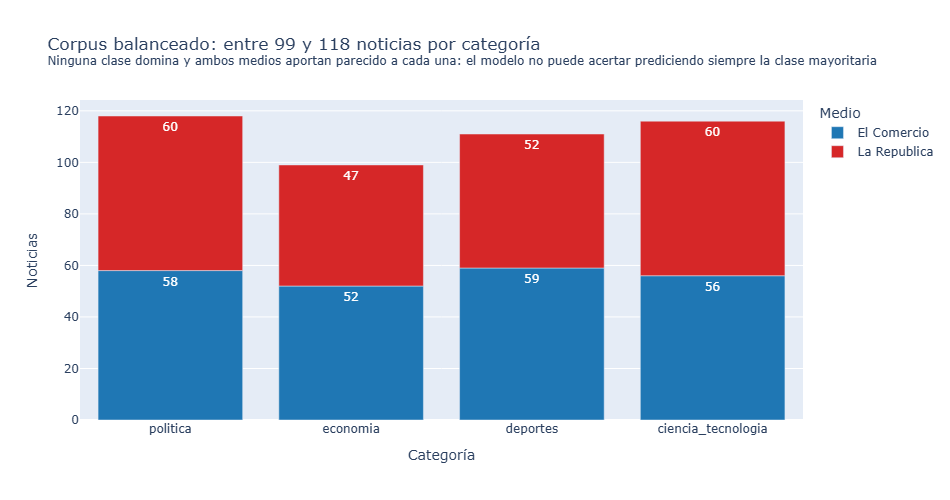

In [10]:
df["fecha_dt"] = pd.to_datetime(df["fecha"], errors="coerce")
df["largo_titular"] = df["titular"].str.len()
COLORES_MEDIO = {"El Comercio": "#1f77b4", "La Republica": "#d62728"}

n_cat = df["etiqueta"].value_counts().reindex(CATEGORIAS)
por_medio_cat = df.groupby(["etiqueta", "medio"]).size().rename("noticias").reset_index()
fig1 = px.bar(
    por_medio_cat, x="etiqueta", y="noticias", color="medio", text="noticias",
    category_orders={"etiqueta": CATEGORIAS}, color_discrete_map=COLORES_MEDIO,
    labels={"etiqueta": "Categoría", "noticias": "Noticias", "medio": "Medio"},
    title=(f"Corpus balanceado: entre {n_cat.min()} y {n_cat.max()} noticias por categoría"
           f"<br><sup>Ninguna clase domina y ambos medios aportan parecido a cada una: el modelo no puede "
           f"acertar prediciendo siempre la clase mayoritaria</sup>"),
)
fig1.show()

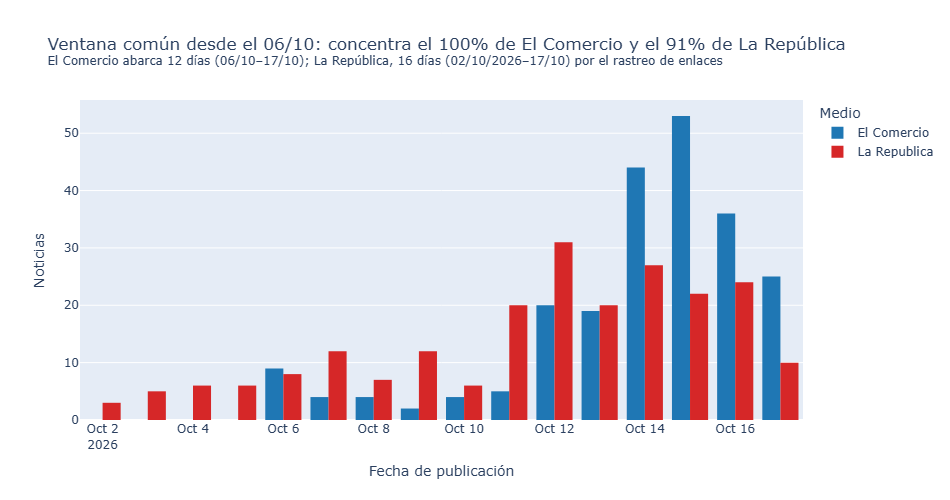

,min,max,dias,count
medio,,,,
El Comercio,2026-10-06,2026-10-17,12,225
La Republica,2026-10-02,2026-10-17,16,219


In [11]:
rango = df.groupby("medio")["fecha_dt"].agg(["min", "max", "count"])
rango["dias"] = (rango["max"] - rango["min"]).dt.days + 1
ec, lr = rango.loc["El Comercio"], rango.loc["La Republica"]
inicio_comun = max(ec["min"], lr["min"])
en_ventana = (df["fecha_dt"] >= inicio_comun).groupby(df["medio"]).mean()

fig2 = px.histogram(
    df, x="fecha_dt", color="medio", barmode="group", color_discrete_map=COLORES_MEDIO,
    labels={"fecha_dt": "Fecha de publicación", "medio": "Medio"},
    title=(f"Ventana común desde el {inicio_comun:%d/%m}: concentra el {en_ventana['El Comercio']:.0%} de El Comercio "
           f"y el {en_ventana['La Republica']:.0%} de La República"
           f"<br><sup>El Comercio abarca {ec['dias']} días ({ec['min']:%d/%m}–{ec['max']:%d/%m}); "
           f"La República, {lr['dias']} días ({lr['min']:%d/%m/%Y}–{lr['max']:%d/%m}) por el rastreo de enlaces</sup>"),
)
fig2.update_layout(yaxis_title="Noticias")
fig2.show()
display(rango[["min", "max", "dias", "count"]])

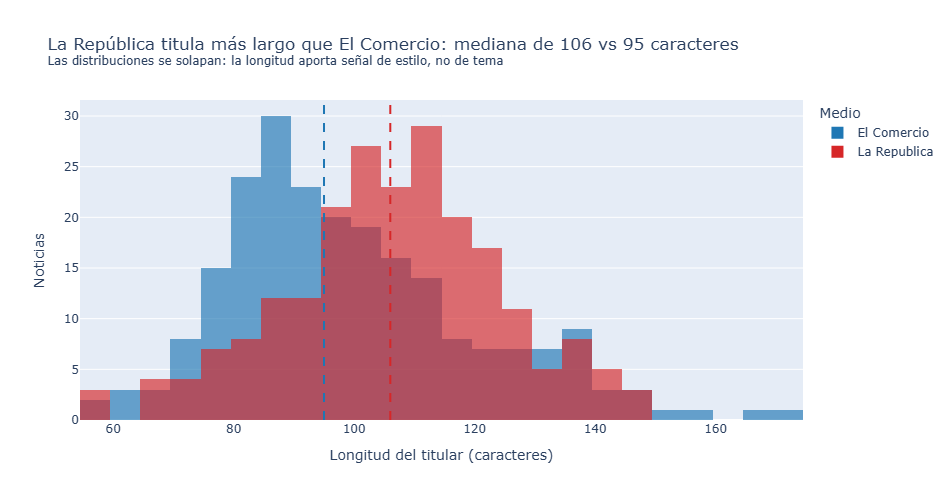

etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,92.0,94.0,88.0,107.0
La Republica,117.0,108.0,101.0,104.0


In [12]:
mediana = df.groupby("medio")["largo_titular"].median()
medio_largo, medio_corto = mediana.idxmax(), mediana.idxmin()
fig3 = px.histogram(
    df, x="largo_titular", color="medio", nbins=30, barmode="overlay", opacity=0.65,
    color_discrete_map=COLORES_MEDIO,
    labels={"largo_titular": "Longitud del titular (caracteres)", "medio": "Medio"},
    title=(f"{medio_largo.replace('Republica', 'República')} titula más largo que "
           f"{medio_corto.replace('Republica', 'República')}: mediana de {mediana.max():.0f} vs {mediana.min():.0f} caracteres"
           f"<br><sup>Las distribuciones se solapan: la longitud aporta señal de estilo, no de tema</sup>"),
)
for medio, valor in mediana.items():
    fig3.add_vline(x=valor, line_dash="dash", line_color=COLORES_MEDIO[medio])
fig3.update_layout(yaxis_title="Noticias")
fig3.show()
display(df.groupby(["medio", "etiqueta"])["largo_titular"].median().unstack().round(0))

## 8. Validación: titulares más largos y más cortos

Se revisa que los extremos sean titulares reales (no menús, firmas ni texto basura) y que sus longitudes coincidan
con las colas del histograma.

In [13]:
columnas = ["largo_titular", "medio", "etiqueta", "titular"]
print("5 titulares MÁS LARGOS:")
display(df.nlargest(5, "largo_titular")[columnas])
print("5 titulares MÁS CORTOS:")
display(df.nsmallest(5, "largo_titular")[columnas])
print(f"Mínimo: {df['largo_titular'].min()} | máximo: {df['largo_titular'].max()} caracteres "
      f"(deben coincidir con los extremos del histograma)")

5 titulares MÁS LARGOS:


,largo_titular,medio,etiqueta,titular
166,171,El Comercio,deportes,"“Con Mano Menezes el mejor jugador de la selección ha sido un ecuatoriano”: Bruno Cavassa, Coki Gonzales, ..."
121,167,El Comercio,deportes,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandini le responde a El C...
57,159,El Comercio,politica,Ernesto Álvarez sobre lucha contra la extorsión: “Este delito no se combate con presencia policial en la c...
99,153,El Comercio,economia,"Justin Trudeau, exprimer ministro de Canadá, sobre crisis de turismo en EE.UU.: “No han sido muy buenos ha..."
258,148,La Republica,deportes,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Cop..."


5 titulares MÁS CORTOS:


,largo_titular,medio,etiqueta,titular
388,56,La Republica,politica,Vaticano informa que Papa León XIV tiene cáncer pulmonar
318,57,La Republica,deportes,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?
476,58,La Republica,politica,Gobierno plantea regulación de armas de fuego de uso civil
211,59,El Comercio,ciencia_tecnologia,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"
192,59,El Comercio,ciencia_tecnologia,¿Qué secreto de longevidad atesora una tortuga de 194 años?


Mínimo: 56 | máximo: 171 caracteres (deben coincidir con los extremos del histograma)


### Lectura del EDA

* **Balance.** Las 4 categorías tienen entre 99 y 118 noticias, y cada medio aporta entre 47 y 60 a cada una
  (225 de El Comercio y 219 de La República). Economía es la más chica porque en La República perdió las series
  diarias del precio del dólar.
* **Cobertura temporal.** El Comercio abarca 12 días (06–17 de octubre) y La República 16 (02–17 de octubre). El
  91 % de las notas de La República cae en la ventana del 06 al 17 de octubre, así que ambos medios cubren casi la
  misma agenda. Eso permite buscar la misma noticia contada por los dos diarios en el análisis de sesgo.
* **Estilo.** La República titula más largo (mediana de 106 contra 95 caracteres), sobre todo en ciencia y
  tecnología (117 contra 91,5): sus titulares de ciencia son narrativos (*"Un descubrimiento inesperado en
  Chernóbil..."*), mientras que El Comercio es más directo. La excepción es política, donde El Comercio titula más
  largo porque suele citar declaraciones entre comillas.
* **Validación.** Los extremos (56 y 171 caracteres) son titulares reales y completos que coinciden con las colas del
  histograma. Los más largos son citas textuales; los más cortos, preguntas o enunciados directos. No se coló
  texto basura (menús, firmas, avisos).
* **Ruido de la etiqueta editorial.** La etiqueta sale de la sección donde el diario publicó la nota, no de su
  contenido. Por ejemplo, La República publica en `politica` las noticias sobre la salud del Papa. Ese ruido se
  mide en la Parte 2 al comparar con el LLM.

## 9. Exportación de `datos/noticias.csv`

Se guardan las 7 columnas obligatorias y se verifican con `assert` las condiciones de la tarea.

In [14]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = (df.sort_values(["medio", "etiqueta", "fecha"], ascending=[True, True, False])[COLUMNAS]
           .reset_index(drop=True))
final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

assert list(final.columns) == COLUMNAS
assert final["url"].is_unique and final["titular"].is_unique
assert final["etiqueta"].isin(CATEGORIAS).all()
assert final["url"].str.startswith("https://").all()
assert (final["medio"].value_counts() >= 200).all(), "Cada medio debe aportar al menos 200 noticias"

print("df.shape:", final.shape)
display(final.head(5))

df.shape: (444, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,"“Grand Theft Auto VI” lanza un tráiler con una escena de sexo, la ocasión donde esto los metió en problemas","Como “Hot Coffee”, un minijuego oculto en “Grand Theft Auto: San Andreas”, llevó a pérdidas millonarias y ...",El Comercio,tecnologia/videojuegos,https://elcomercio.pe/tecnologia/videojuegos/grand-theft-auto-vi-lanza-un-trailer-con-una-escena-de-sexo-l...,2026-10-17,ciencia_tecnologia
1,"iPhone Duo se agota a minutos de abierta su preventa, ahora disponibles a partir del 22 de enero","El flamante celular plegable, que estará disponible a partir del 23 de octubre, se mostró extremadamente p...",El Comercio,tecnologia/moviles,https://elcomercio.pe/tecnologia/moviles/iphone-duo-se-agota-a-minutos-de-abiertas-sus-preordenes-ahora-di...,2026-10-17,ciencia_tecnologia
2,La IA ayuda a los historiadores a descifrar mensajes napoleónicos y papiros carbonizados,"Mensajes secretos de más de 200 años fueron descifrados en un proyecto llamado “Back in time”, de Francia,...",El Comercio,tecnologia/inteligencia-artificial,https://elcomercio.pe/tecnologia/inteligencia-artificial/la-ia-ayuda-a-los-historiadores-a-descifrar-mensa...,2026-10-16,ciencia_tecnologia
3,"Efecto cine, batería de emergencia o verificación: cinco novedades del iPhone 18","El nuevo teléfono de Apple está en el mercado y plantea soluciones en fotografía profesional, capacidad de...",El Comercio,tecnologia/moviles,https://elcomercio.pe/tecnologia/moviles/efecto-cine-bateria-de-emergencia-o-verificacion-cinco-novedades-...,2026-10-16,ciencia_tecnologia
4,La alerta de seísmos de Google está disponible ya en 200 países de todo el mundo,"Google ha anunciado una actualización de la alerta ‘Preparáte’, y mostrará un mapa de la zona donde se han...",El Comercio,tecnologia/actualidad,https://elcomercio.pe/tecnologia/actualidad/la-alerta-de-seismos-de-google-esta-disponible-ya-en-200-paise...,2026-10-16,ciencia_tecnologia
